In [1]:
from google.colab import drive

In [3]:
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Import data analysis libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import TensorFlow
import tensorflow as tf

# File and image handling
from pathlib import Path
from PIL import Image

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Check TensorFlow version and GPU
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [5]:

# Your Google Drive project directory
project_dir = Path(
    "/content/drive/MyDrive/Colab_Notebooks/A_DREAM_JOB"
)

# Expected dataset directory
data_dir = project_dir / "5_Deep_Learning" / "ISL_Dataset"

# Verify the actual folder location
if not data_dir.is_dir():
    print("Dataset not found at:", data_dir)
    print("\nFolders available in the project directory:")

    for folder in sorted(project_dir.iterdir()):
        if folder.is_dir():
            print(folder.name)

    raise FileNotFoundError(
        "Update data_dir to your actual ISL_Dataset folder."
    )

# Each alphabet folder represents one class
classes = sorted([
    folder.name
    for folder in data_dir.iterdir()
    if folder.is_dir()
])

print("Dataset location:", data_dir)
print("Total classes:", len(classes))
print("Alphabet classes:", classes)


Dataset location: /content/drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/5_Deep_Learning/ISL_Dataset
Total classes: 23
Alphabet classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Z']


In [6]:
#Count images and inspect dimensions


# Supported image formats
image_extensions = {".jpg", ".jpeg", ".png"}

# Store image information
records = []
image_paths = []

for class_name in classes:

    # Access the alphabet folder
    class_folder = data_dir / class_name

    # Collect images belonging to this class
    images = sorted([
        file for file in class_folder.iterdir()
        if file.suffix.lower() in image_extensions
    ])

    # Save the class count
    records.append({
        "Class": class_name,
        "Image_Count": len(images)
    })

    image_paths.extend(images)

# Convert statistics into a DataFrame
df = pd.DataFrame(records)

display(df)

print("Total images:", len(image_paths))
print("Total classes:", len(classes))
print("Minimum images per class:", df["Image_Count"].min())
print("Maximum images per class:", df["Image_Count"].max())

# Inspect the dimensions of one actual image
with Image.open(image_paths[0]) as img:
    print("Sample image dimensions:", img.size)
    print("Sample image mode:", img.mode)


,Class,Image_Count
0,A,25
1,B,38
2,C,34
3,D,34
4,E,46
5,F,21
6,G,29
7,I,30
8,K,36
9,L,36


Total images: 702
Total classes: 23
Minimum images per class: 21
Maximum images per class: 46
Sample image dimensions: (128, 128)
Sample image mode: RGB


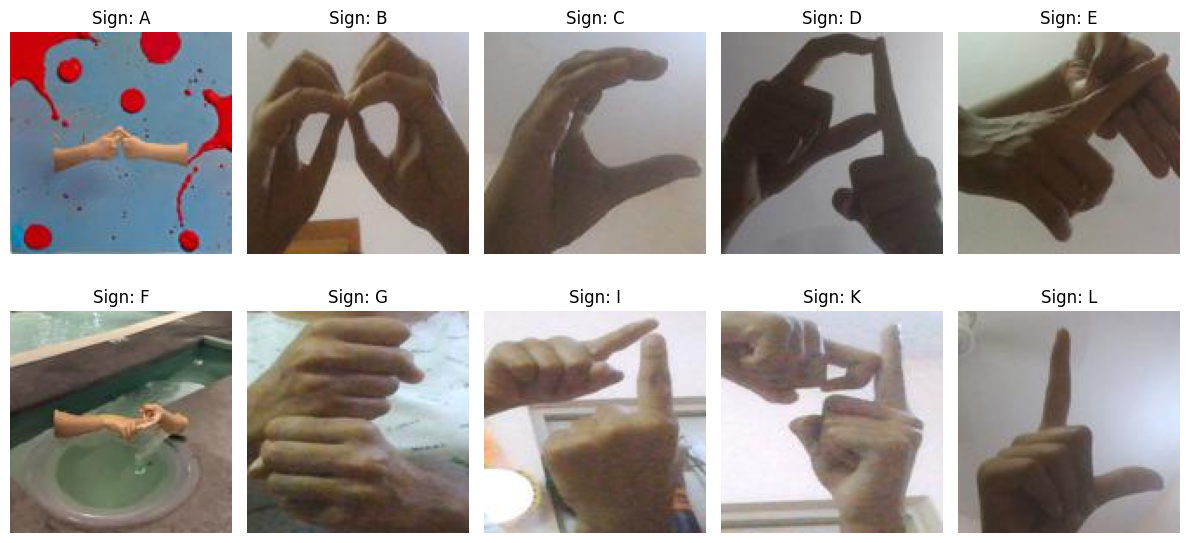

In [7]:
# Display ISL gestures

# Create a 2x5 image grid
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

# Display one image from each of the first 10 classes
for ax, class_name in zip(axes.flat, classes[:10]):

    class_folder = data_dir / class_name

    # Select the first image from this class
    image_path = next(
        file for file in sorted(class_folder.iterdir())
        if file.suffix.lower() in image_extensions
    )

    # Open image in RGB format
    sample_image = Image.open(image_path).convert("RGB")

    ax.imshow(sample_image)
    ax.set_title(f"Sign: {class_name}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [8]:
# Create and normalize a tensor


# Select an image from alphabet A
image_path = next(
    file for file in sorted((data_dir / "A").iterdir())
    if file.suffix.lower() in image_extensions
)

# Load image as RGB
image = Image.open(image_path).convert("RGB")

# Resize to match our PyTorch model
image = image.resize((128, 128))

# Convert PIL image into NumPy array
image_array = np.asarray(image, dtype=np.float32)

# Convert NumPy array into TensorFlow tensor
image_tensor = tf.convert_to_tensor(
    image_array,
    dtype=tf.float32
)

# Normalize pixel values from 0–255 to 0–1
image_tensor = image_tensor / 255.0

print("Tensor shape:", image_tensor.shape)
print("Tensor dtype:", image_tensor.dtype)
print("Minimum value:", tf.reduce_min(image_tensor).numpy())
print("Maximum value:", tf.reduce_max(image_tensor).numpy())


Tensor shape: (128, 128, 3)
Tensor dtype: <dtype: 'float32'>
Minimum value: 0.0
Maximum value: 0.972549


In [9]:
# Indexing, arithmetic, and batch dimensions


# 1. Tensor indexing: extract red channel
red_channel = image_tensor[:, :, 0]

# 2. Tensor reduction: calculate mean pixel intensity
mean_intensity = tf.reduce_mean(image_tensor)

# 3. Tensor arithmetic: increase brightness
brighter_tensor = tf.clip_by_value(
    image_tensor * 1.2,
    clip_value_min=0.0,
    clip_value_max=1.0
)

# 4. Add a batch dimension
# (128, 128, 3) -> (1, 128, 128, 3)
batch = tf.expand_dims(image_tensor, axis=0)

print("Original tensor:", image_tensor.shape)
print("Red channel:", red_channel.shape)
print("Mean intensity:", mean_intensity.numpy())
print("Brighter tensor:", brighter_tensor.shape)
print("Batch shape:", batch.shape)


Original tensor: (128, 128, 3)
Red channel: (128, 128)
Mean intensity: 0.47303882
Brighter tensor: (128, 128, 3)
Batch shape: (1, 128, 128, 3)


Function	Purpose

tf.convert_to_tensor()	Creates a TensorFlow tensor

tf.reduce_mean()	Calculates the mean of tensor values

tf.reduce_min()	Finds the minimum value

tf.clip_by_value()	Restricts values to a specified range

tf.expand_dims()	Adds a new tensor dimension

.numpy()	Converts an eager tensor to a NumPy representation

In [10]:
# Define the neural network

from tensorflow import keras
from tensorflow.keras import layers

# Number of output classes from Exercise 1
num_classes = len(classes)

# Build a CNN using the Keras Sequential API
model = keras.Sequential([

    # Define the expected image shape
    keras.Input(shape=(128, 128, 3)),

    # Block 1: Learn 16 image feature maps
    layers.Conv2D(
        filters=16,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    # Reduce spatial dimensions by half
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Block 2: Learn 32 more complex feature maps
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    # Reduce spatial dimensions again
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convert each feature map into one average value
    layers.GlobalAveragePooling2D(),

    # Output one raw score per alphabet class
    layers.Dense(num_classes)

], name="ISL_TensorFlow_CNN")

print("CNN created successfully.")


CNN created successfully.


TensorFlow	PyTorch equivalent	Purpose

Conv2D	nn.Conv2d	Extract image features

activation="relu"	nn.ReLU	Introduce nonlinearity

MaxPooling2D	nn.MaxPool2d	Reduce spatial dimensions

GlobalAveragePooling2D	nn.AdaptiveAvgPool2d((1,1)) + flatten	Convert feature maps into feature values

Dense	nn.Linear	Produce class scores

In [11]:
# Model summary and trainable parameters


# Display layers, output shapes, and parameter counts
model.summary()

# Calculate total trainable parameters
trainable_params = sum(
    int(tf.size(variable).numpy())
    for variable in model.trainable_variables
)

print("Total trainable parameters:", trainable_params)


Model: "ISL_TensorFlow_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 23)             │           759 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,847 (22.84 KB)

 Trainable params: 5,847 (22.84 KB)

 Non-trainable params: 0 (0.00 B)

Total trainable parameters: 5847


In [12]:
# Pass an ISL image through the CNN


# Forward propagation using our ISL image batch
# training=False tells Keras this is an inference pass
outputs = model(batch, training=False)

# Display input and output shapes
print("Input shape:", batch.shape)
print("Output shape:", outputs.shape)

# Display raw class scores
print("Raw logits:", outputs.numpy())


Input shape: (1, 128, 128, 3)
Output shape: (1, 23)
Raw logits: [[-0.08910663  0.06547883  0.05480072  0.11316527  0.09847688 -0.1409142
  -0.04558914  0.09822138 -0.10568917  0.01127808 -0.02960806  0.02182111
  -0.05759494  0.15358981 -0.1977237  -0.12756482 -0.0266987  -0.01148323
   0.03735644  0.07073515 -0.0260791   0.00896027  0.06595429]]


In [13]:
# Inspect intermediate layer outputs


# Create a model that exposes intermediate layer outputs
intermediate_model = keras.Model(
    inputs=model.inputs,
    outputs=[layer.output for layer in model.layers]
)

# Run the image through all layers
intermediate_outputs = intermediate_model(
    batch,
    training=False
)

# Display the output shape after each layer
for layer, output in zip(
    model.layers,
    intermediate_outputs
):
    print(
        f"{layer.name:30s} -> {tuple(output.shape)}"
    )


conv2d                         -> (1, 128, 128, 16)
max_pooling2d                  -> (1, 64, 64, 16)
conv2d_1                       -> (1, 64, 64, 32)
max_pooling2d_1                -> (1, 32, 32, 32)
global_average_pooling2d       -> (1, 32)
dense                          -> (1, 23)


Predicted alphabet: P
Predicted probability: 5.06%


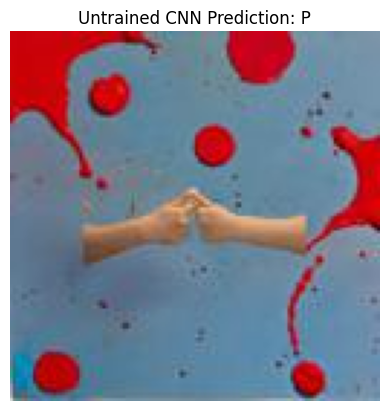

In [14]:
# Predict an alphabet


# Convert raw logits into probabilities
probabilities = tf.nn.softmax(outputs, axis=1)

# Find the index with the highest probability
predicted_index = int(
    tf.argmax(probabilities, axis=1).numpy()[0]
)

# Convert numerical index into alphabet label
predicted_alphabet = classes[predicted_index]

# Retrieve probability for the selected class
predicted_probability = float(
    probabilities[0, predicted_index].numpy()
)

print("Predicted alphabet:", predicted_alphabet)
print(f"Predicted probability: {predicted_probability:.2%}")

# Display the original image from Exercise 1
plt.imshow(image)
plt.title(
    f"Untrained CNN Prediction: {predicted_alphabet}"
)
plt.axis("off")
plt.show()


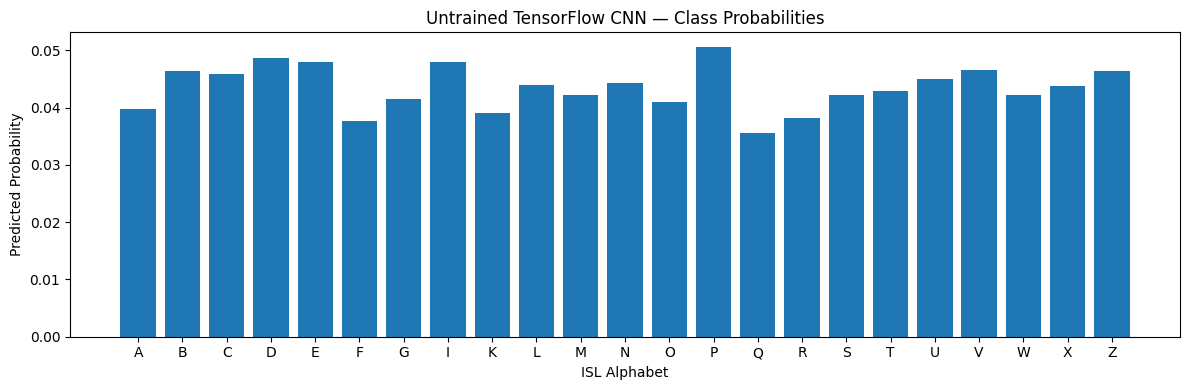

In [15]:
# Prediction distribution


# Convert probabilities into a NumPy array
class_probabilities = probabilities.numpy()[0]

# Plot probability for every alphabet
plt.figure(figsize=(12, 4))

plt.bar(classes, class_probabilities)

plt.xlabel("ISL Alphabet")
plt.ylabel("Predicted Probability")
plt.title("Untrained TensorFlow CNN — Class Probabilities")

plt.tight_layout()
plt.show()


In [16]:
# Sparse Categorical Cross-Entropy


from tensorflow import keras
import tensorflow as tf

# Define the loss function for multiclass classification
criterion = keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)

print("Loss function:", criterion.name)


Loss function: sparse_categorical_crossentropy


In [17]:
# Convert alphabet A into a numerical label


# Actual alphabet of our selected image
actual_class = "A"

# Find its numerical index
target_index = classes.index(actual_class)

# Create target tensor
# SparseCategoricalCrossentropy expects integer labels
target = tf.constant(
    [target_index],
    dtype=tf.int32
)

print("Actual alphabet:", actual_class)
print("Target index:", target_index)
print("Target tensor:", target.numpy())
print("Target shape:", target.shape)


Actual alphabet: A
Target index: 0
Target tensor: [0]
Target shape: (1,)


In [18]:
# Calculate loss using GradientTape


# Record operations needed for automatic differentiation
with tf.GradientTape() as tape:

    # Forward propagation through the CNN
    logits = model(batch, training=True)

    # Compare predicted logits with actual label
    loss = criterion(target, logits)

print("Model output shape:", logits.shape)
print("Target shape:", target.shape)
print("Cross-Entropy Loss:", loss.numpy())


Model output shape: (1, 23)
Target shape: (1,)
Cross-Entropy Loss: 3.2258654


In [19]:
# Calculate gradients


# Compute gradients of loss with respect to trainable weights
gradients = tape.gradient(
    loss,
    model.trainable_variables
)

# Inspect gradient information
for variable, gradient in zip(
    model.trainable_variables,
    gradients
):

    if gradient is not None:

        print(
            f"Weight: {variable.name} | "
            f"Shape: {gradient.shape} | "
            f"Mean Absolute Gradient: "
            f"{tf.reduce_mean(tf.abs(gradient)).numpy():.8f}"
        )


Weight: kernel | Shape: (3, 3, 3, 16) | Mean Absolute Gradient: 0.00884860
Weight: bias | Shape: (16,) | Mean Absolute Gradient: 0.01832377
Weight: kernel | Shape: (3, 3, 16, 32) | Mean Absolute Gradient: 0.00490084
Weight: bias | Shape: (32,) | Mean Absolute Gradient: 0.03975042
Weight: kernel | Shape: (32, 23) | Mean Absolute Gradient: 0.00344447
Weight: bias | Shape: (23,) | Mean Absolute Gradient: 0.08350249


In [20]:
# Examine gradients of the output layer


# The final Dense layer has a weight matrix and bias vector
dense_layer = model.layers[-1]

# Inspect trainable variables
for variable in dense_layer.trainable_variables:

    print("Variable:", variable.name)
    print("Shape:", variable.shape)

# Retrieve gradients for the final Dense layer
dense_gradients = gradients[-2:]

for gradient in dense_gradients:

    print("\nGradient shape:", gradient.shape)

    print(
        "Mean absolute gradient:",
        tf.reduce_mean(tf.abs(gradient)).numpy()
    )


Variable: kernel
Shape: (32, 23)
Variable: bias
Shape: (23,)

Gradient shape: (32, 23)
Mean absolute gradient: 0.0034444707

Gradient shape: (23,)
Mean absolute gradient: 0.08350249


In [21]:
# Backpropagation vs. weight updates


# Save current weights of the final Dense layer
weights_before = dense_layer.kernel.numpy().copy()

# No optimizer update has been performed
weights_after = dense_layer.kernel.numpy().copy()

# Check whether weights changed
weights_changed = not np.array_equal(
    weights_before,
    weights_after
)

# Verify that gradients were calculated
gradients_calculated = all(
    gradient is not None
    for gradient in gradients
)

print("Weights changed:", weights_changed)
print("Gradients calculated:", gradients_calculated)


Weights changed: False
Gradients calculated: True


In [22]:
# Create image paths and labels


from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models

# Supported image formats
image_extensions = {".jpg", ".jpeg", ".png"}

# Store image file paths and numerical labels
image_paths = []
image_labels = []

# Create one numerical label for each alphabet
class_to_idx = {
    class_name: index
    for index, class_name in enumerate(classes)
}

# Collect all image paths and labels
for class_name in classes:

    class_folder = data_dir / class_name

    for file in sorted(class_folder.iterdir()):

        if file.suffix.lower() in image_extensions:

            image_paths.append(str(file))
            image_labels.append(class_to_idx[class_name])

# Convert labels into NumPy array
image_labels = np.array(image_labels, dtype=np.int32)

print("Total images:", len(image_paths))
print("Total classes:", len(classes))
print("Class mapping:", class_to_idx)


Total images: 702
Total classes: 23
Class mapping: {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'I': 7, 'K': 8, 'L': 9, 'M': 10, 'N': 11, 'O': 12, 'P': 13, 'Q': 14, 'R': 15, 'S': 16, 'T': 17, 'U': 18, 'V': 19, 'W': 20, 'X': 21, 'Z': 22}


In [23]:
# Train, validation, and test sets


# Generate image indices
indices = np.arange(len(image_paths))

# Split 80% training and 20% temporary
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=image_labels,
    random_state=42
)

# Split temporary data equally into validation and test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=image_labels[temp_idx],
    random_state=42
)

# Extract image paths and labels for each split
train_paths = [image_paths[i] for i in train_idx]
val_paths = [image_paths[i] for i in val_idx]
test_paths = [image_paths[i] for i in test_idx]

train_labels = image_labels[train_idx]
val_labels = image_labels[val_idx]
test_labels = image_labels[test_idx]

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Test images:", len(test_paths))


Training images: 561
Validation images: 70
Test images: 71


In [24]:
# Load and preprocess images


# Function to load and preprocess an image
def load_image(path, label):

    # Read image from file
    image = tf.io.read_file(path)

    # Decode JPEG or PNG into RGB
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Ensure TensorFlow knows the channel shape
    image.set_shape([None, None, 3])

    # Resize to the same dimensions as PyTorch
    image = tf.image.resize(image, (128, 128))

    # Normalize pixel values to 0–1
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


# Create TensorFlow datasets
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

# Apply image preprocessing
train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("TensorFlow datasets created successfully.")


TensorFlow datasets created successfully.


In [25]:
# Configure batch size and prefetching


# Number of images per training batch
batch_size = 16

# Shuffle only training data
train_ds = (
    train_ds
    .shuffle(
        buffer_size=len(train_paths),
        seed=42,
        reshuffle_each_iteration=True
    )
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

# Validation and test data must not be shuffled
val_ds = (
    val_ds
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

# Inspect one training batch
for images, labels in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)


Image batch shape: (16, 128, 128, 3)
Label batch shape: (16,)


In [26]:
# Initialize Adam and the loss function


# Reset the model for a fresh training experiment
tf.keras.utils.set_random_seed(42)

# Recreate the same CNN architecture
model = tf.keras.Sequential([

    tf.keras.Input(shape=(128, 128, 3)),

    layers.Conv2D(
        16, (3, 3),
        padding="same",
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        32, (3, 3),
        padding="same",
        activation="relu"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    # Raw logits for each alphabet
    layers.Dense(len(classes))

])

# Cross-entropy loss for integer class labels
criterion = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)

# Adam optimizer
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001
)

print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", float(optimizer.learning_rate.numpy()))


Optimizer: Adam
Learning rate: 0.0010000000474974513


In [27]:
# Complete TensorFlow training loop


# Number of complete training passes
epochs = 10

# Store training and validation metrics
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(epochs):

    # -------------------------
    # TRAINING PHASE
    # -------------------------

    train_loss_metric = tf.keras.metrics.Mean()
    train_acc_metric = tf.keras.metrics.SparseCategoricalAccuracy()

    for images, labels in train_ds:

        # 1. Record forward operations
        with tf.GradientTape() as tape:

            # 2. Forward propagation
            logits = model(images, training=True)

            # 3. Calculate loss
            loss = criterion(labels, logits)

        # 4. Calculate gradients
        gradients = tape.gradient(
            loss,
            model.trainable_variables
        )

        # 5. Update model weights
        optimizer.apply_gradients(
            zip(gradients, model.trainable_variables)
        )

        # Update training metrics
        train_loss_metric.update_state(
            loss,
            sample_weight=tf.shape(labels)[0]
        )

        train_acc_metric.update_state(labels, logits)

    # -------------------------
    # VALIDATION PHASE
    # -------------------------

    val_loss_metric = tf.keras.metrics.Mean()
    val_acc_metric = tf.keras.metrics.SparseCategoricalAccuracy()

    for images, labels in val_ds:

        # Forward propagation without weight updates
        logits = model(images, training=False)

        # Calculate validation loss
        loss = criterion(labels, logits)

        # Update validation metrics
        val_loss_metric.update_state(
            loss,
            sample_weight=tf.shape(labels)[0]
        )

        val_acc_metric.update_state(labels, logits)

    # Extract metrics
    train_loss = float(train_loss_metric.result().numpy())
    val_loss = float(val_loss_metric.result().numpy())

    train_accuracy = float(train_acc_metric.result().numpy())
    val_accuracy = float(val_acc_metric.result().numpy())

    # Save epoch results
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    # Print progress
    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2%}"
    )


Epoch [1/10] | Train Loss: 3.1392 | Train Acc: 4.10% | Val Loss: 3.1332 | Val Acc: 5.71%
Epoch [2/10] | Train Loss: 3.1317 | Train Acc: 6.60% | Val Loss: 3.1329 | Val Acc: 5.71%
Epoch [3/10] | Train Loss: 3.1275 | Train Acc: 4.63% | Val Loss: 3.1325 | Val Acc: 5.71%
Epoch [4/10] | Train Loss: 3.1247 | Train Acc: 6.60% | Val Loss: 3.1327 | Val Acc: 5.71%
Epoch [5/10] | Train Loss: 3.1226 | Train Acc: 6.60% | Val Loss: 3.1318 | Val Acc: 5.71%
Epoch [6/10] | Train Loss: 3.1239 | Train Acc: 5.35% | Val Loss: 3.1302 | Val Acc: 5.71%
Epoch [7/10] | Train Loss: 3.1203 | Train Acc: 6.06% | Val Loss: 3.1317 | Val Acc: 4.29%
Epoch [8/10] | Train Loss: 3.1153 | Train Acc: 6.95% | Val Loss: 3.1327 | Val Acc: 4.29%
Epoch [9/10] | Train Loss: 3.1151 | Train Acc: 6.42% | Val Loss: 3.1313 | Val Acc: 5.71%
Epoch [10/10] | Train Loss: 3.1131 | Train Acc: 6.95% | Val Loss: 3.1330 | Val Acc: 7.14%


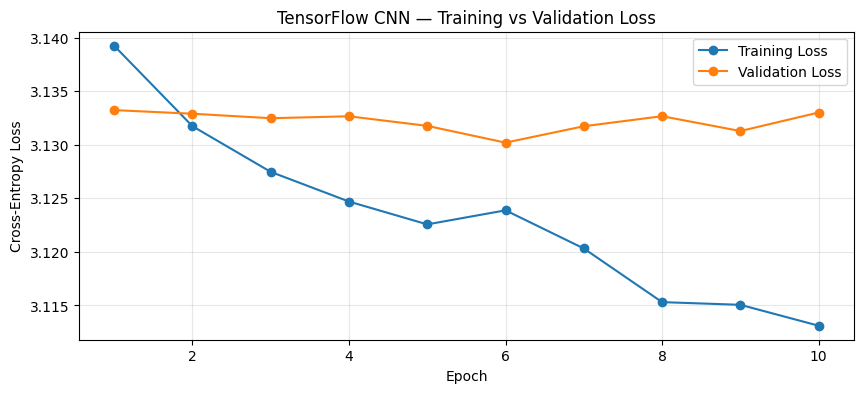

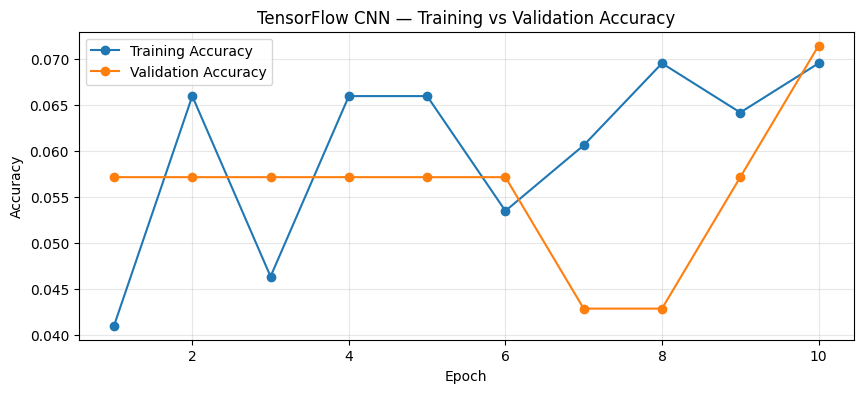

In [28]:
# Plot training and validation curves


# Generate epoch numbers
epoch_numbers = range(1, epochs + 1)

# Plot loss
plt.figure(figsize=(10, 4))

plt.plot(
    epoch_numbers,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epoch_numbers,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("TensorFlow CNN — Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot accuracy
plt.figure(figsize=(10, 4))

plt.plot(
    epoch_numbers,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epoch_numbers,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("TensorFlow CNN — Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [29]:
# Identify the best validation epoch


# Find the epoch with minimum validation loss
best_epoch = int(np.argmin(history["val_loss"]))

print("Best epoch:", best_epoch + 1)

print(
    "Best validation loss:",
    round(history["val_loss"][best_epoch], 4)
)

print(
    "Validation accuracy at best epoch:",
    f"{history['val_accuracy'][best_epoch]:.2%}"
)

print(
    "Final training accuracy:",
    f"{history['train_accuracy'][-1]:.2%}"
)


Best epoch: 6
Best validation loss: 3.1302
Validation accuracy at best epoch: 5.71%
Final training accuracy: 6.95%


In [30]:
# Evaluate the test dataset


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Store actual labels and model predictions
y_true = []
y_pred = []

# Track test loss
test_loss_sum = 0.0
total_images = 0

# Evaluate each test batch
for images, labels in test_ds:

    # Forward propagation in inference mode
    logits = model(images, training=False)

    # Calculate cross-entropy loss
    loss = criterion(labels, logits)

    # Convert logits into predicted class indices
    predictions = tf.argmax(
        logits,
        axis=1,
        output_type=tf.int32
    )

    # Accumulate sample-weighted loss
    batch_size = int(tf.shape(labels)[0].numpy())

    test_loss_sum += float(loss.numpy()) * batch_size
    total_images += batch_size

    # Store actual and predicted labels
    y_true.extend(labels.numpy().tolist())
    y_pred.extend(predictions.numpy().tolist())

# Calculate average test loss
test_loss = test_loss_sum / total_images

print("Total test images:", total_images)
print(f"Average test loss: {test_loss:.4f}")


Total test images: 71
Average test loss: 3.0979


In [31]:
# Accuracy, Precision, Recall, and F1


# Overall accuracy
accuracy = accuracy_score(y_true, y_pred)

# Macro precision: equal weight to every class
precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    labels=range(len(classes)),
    zero_division=0
)

# Macro recall
recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    labels=range(len(classes)),
    zero_division=0
)

# Macro F1-score
f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    labels=range(len(classes)),
    zero_division=0
)

# Create a summary table
metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

display(
    metrics_df.style.format({"Score": "{:.2%}"})
)


,Metric,Score
0,Accuracy,8.45%
1,Macro Precision,0.83%
2,Macro Recall,5.65%
3,Macro F1-Score,1.42%


In [32]:
# Classification report


# Generate per-class evaluation metrics
report = classification_report(
    y_true,
    y_pred,
    labels=range(len(classes)),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

# Convert results into a DataFrame
report_df = pd.DataFrame(report).T

# Display individual alphabet performance
display(
    report_df.loc[
        classes,
        ["precision", "recall", "f1-score", "support"]
    ].sort_values("f1-score")
)


,precision,recall,f1-score,support
A,0.000000,0.0,0.000000,2.0
B,0.000000,0.0,0.000000,4.0
C,0.000000,0.0,0.000000,4.0
D,0.000000,0.0,0.000000,4.0
F,0.000000,0.0,0.000000,2.0
G,0.000000,0.0,0.000000,3.0
I,0.000000,0.0,0.000000,3.0
L,0.000000,0.0,0.000000,4.0
Q,0.000000,0.0,0.000000,4.0
M,0.000000,0.0,0.000000,3.0


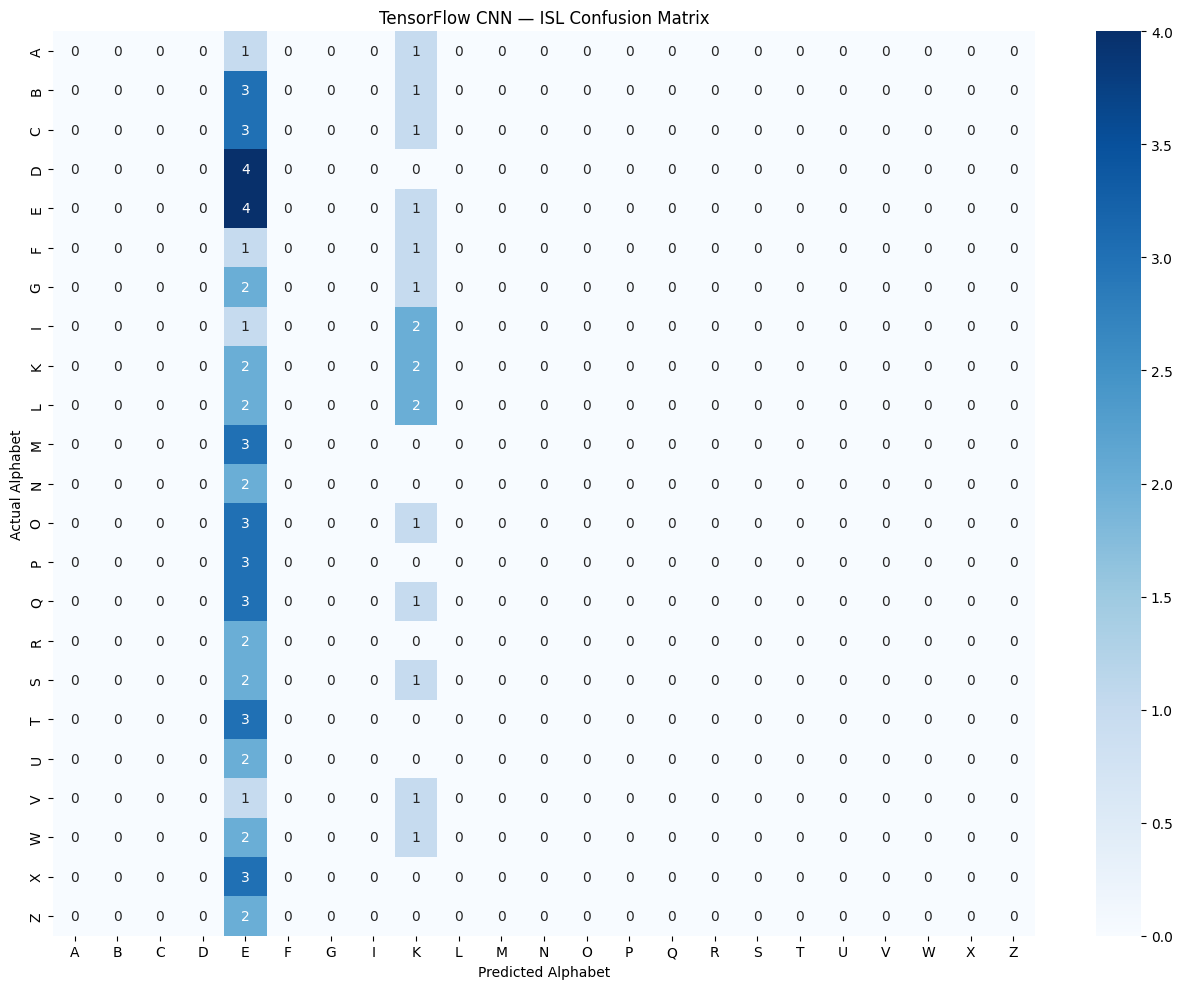

In [33]:
# Confusion matrix heatmap


import seaborn as sns

# Calculate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(classes))
)

# Display heatmap
plt.figure(figsize=(13, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Alphabet")
plt.ylabel("Actual Alphabet")
plt.title("TensorFlow CNN — ISL Confusion Matrix")

plt.tight_layout()
plt.show()


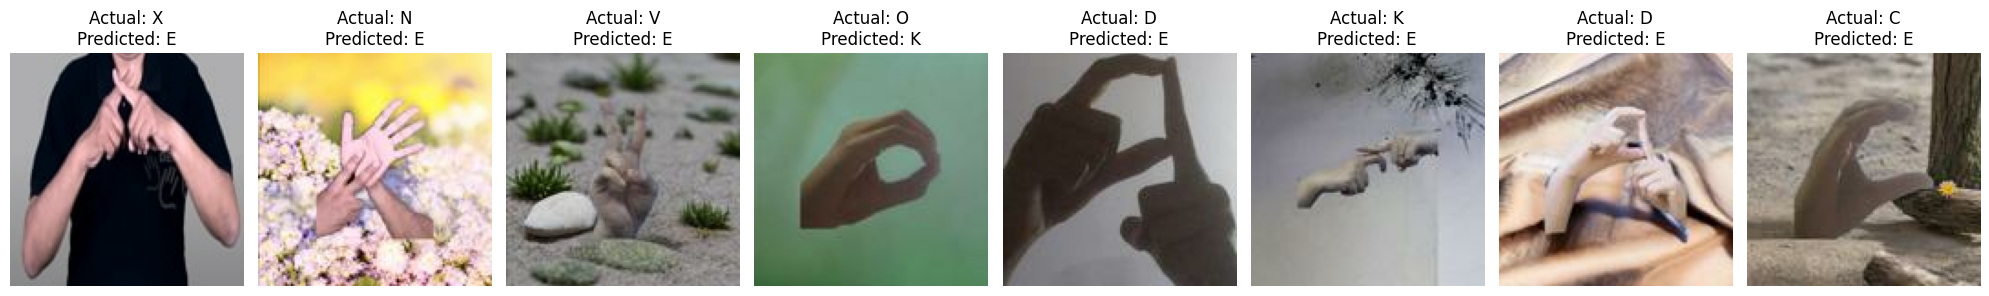

In [34]:
# Visualize misclassified ISL images


# Store incorrectly classified images
wrong_predictions = []

# Evaluate test images
for images, labels in test_ds:

    # Generate predictions
    logits = model(images, training=False)

    predictions = tf.argmax(
        logits,
        axis=1,
        output_type=tf.int32
    )

    # Compare predictions with actual labels
    for image, actual, predicted in zip(
        images.numpy(),
        labels.numpy(),
        predictions.numpy()
    ):

        if actual != predicted:

            wrong_predictions.append({
                "image": image,
                "actual": int(actual),
                "predicted": int(predicted)
            })

# Display up to 8 incorrect predictions
num_examples = min(8, len(wrong_predictions))

if num_examples == 0:
    print("No incorrect predictions found.")

else:
    fig, axes = plt.subplots(
        1,
        num_examples,
        figsize=(2.5 * num_examples, 3)
    )

    axes = np.atleast_1d(axes)

    for ax, example in zip(
        axes,
        wrong_predictions[:num_examples]
    ):

        ax.imshow(example["image"])

        ax.set_title(
            f"Actual: {classes[example['actual']]}\n"
            f"Predicted: {classes[example['predicted']]}"
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [35]:
# Analyze classification errors


# Copy the confusion matrix
errors = cm.copy()

# Remove correct predictions from the diagonal
np.fill_diagonal(errors, 0)

# Store misclassification pairs
confusion_pairs = []

for actual_idx in range(len(classes)):

    for predicted_idx in range(len(classes)):

        count = errors[actual_idx, predicted_idx]

        if count > 0:

            confusion_pairs.append({
                "Actual": classes[actual_idx],
                "Predicted": classes[predicted_idx],
                "Mistakes": int(count)
            })

# Create DataFrame
confusion_df = pd.DataFrame(
    confusion_pairs,
    columns=["Actual", "Predicted", "Mistakes"]
)

# Display the most frequent mistakes
display(
    confusion_df.sort_values(
        "Mistakes",
        ascending=False
    ).head(10)
)


,Actual,Predicted,Mistakes
6,D,E,4
4,C,E,3
2,B,E,3
27,T,E,3
22,Q,E,3
17,M,E,3
33,X,E,3
21,P,E,3
19,O,E,3
34,Z,E,2


In [36]:
# Evidence-based evaluation summary


# Get individual alphabet F1 scores
class_scores = report_df.loc[classes]

# Identify best and worst performing classes
best_class = class_scores["f1-score"].idxmax()
worst_class = class_scores["f1-score"].idxmin()

# Count incorrect predictions
total_errors = sum(
    actual != predicted
    for actual, predicted in zip(y_true, y_pred)
)

print("TENSORFLOW — ISL MODEL EVALUATION")
print("-" * 45)

print("Test images:", len(y_true))
print("Correct predictions:", len(y_true) - total_errors)
print("Incorrect predictions:", total_errors)

print(f"Test accuracy: {accuracy:.2%}")
print(f"Macro F1-score: {f1:.2%}")

print("Best performing alphabet:", best_class)
print("Lowest performing alphabet:", worst_class)

print("\nBusiness Conclusion:")

if accuracy >= 0.90 and f1 >= 0.90:
    print(
        "Strong preliminary performance on this test split. "
        "Further evaluation on new signers and environments is required."
    )

elif accuracy >= 0.70 and f1 >= 0.70:
    print(
        "Promising baseline performance, but classification "
        "errors require investigation before deployment."
    )

else:
    print(
        "The current CNN needs improvement. Investigate "
        "data quality, model architecture, and training strategy."
    )


TENSORFLOW — ISL MODEL EVALUATION
---------------------------------------------
Test images: 71
Correct predictions: 6
Incorrect predictions: 65
Test accuracy: 8.45%
Macro F1-score: 1.42%
Best performing alphabet: K
Lowest performing alphabet: A

Business Conclusion:
The current CNN needs improvement. Investigate data quality, model architecture, and training strategy.


In [37]:
# Save the model to Google Drive


# Define the model saving location
model_path = (
    "/content/drive/MyDrive/Colab_Notebooks/"
    "A_DREAM_JOB/5_Deep_Learning/isl_tensorflow_model.keras"
)

# Save the trained CNN architecture and weights
model.save(model_path)

print("TensorFlow model saved successfully.")
print("Location:", model_path)


TensorFlow model saved successfully.
Location: /content/drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/5_Deep_Learning/isl_tensorflow_model.keras


In [38]:

import json
from pathlib import Path

# Save alphabet labels alongside the model
labels_path = Path(model_path).with_name(
    "isl_tensorflow_labels.json"
)

# Write class names in their original order
with open(labels_path, "w") as file:
    json.dump(classes, file, indent=4)

print("Class labels saved successfully.")
print("Location:", labels_path)


Class labels saved successfully.
Location: /content/drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/5_Deep_Learning/isl_tensorflow_labels.json


In [39]:
# Load model and labels


# Load trained TensorFlow model
loaded_model = tf.keras.models.load_model(model_path)

# Load saved alphabet labels
with open(labels_path, "r") as file:
    loaded_classes = json.load(file)

# Verify model architecture
loaded_model.summary()

print("Model loaded successfully.")
print("Total classes:", len(loaded_classes))
print("Alphabet labels:", loaded_classes)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 23)             │           759 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,847 (22.84 KB)

 Trainable params: 5,847 (22.84 KB)

 Non-trainable params: 0 (0.00 B)

Model loaded successfully.
Total classes: 23
Alphabet labels: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Z']


In [40]:
# Create a reusable prediction function


from PIL import Image
import numpy as np

def predict_isl(image_path, model, class_names):
    """
    Predict an ISL alphabet from an image.

    Args:
        image_path: Path to image
        model: Trained TensorFlow CNN
        class_names: Saved alphabet labels

    Returns:
        Predicted alphabet and probability
    """

    # Open image and convert to RGB
    image = Image.open(image_path).convert("RGB")

    # Resize image to CNN input dimensions
    image = image.resize((128, 128))

    # Convert image to a NumPy array
    image_array = np.asarray(
        image,
        dtype=np.float32
    )

    # Normalize pixel values to 0–1
    image_array = image_array / 255.0

    # Add batch dimension
    image_batch = np.expand_dims(
        image_array,
        axis=0
    )

    # Forward propagation
    logits = model(image_batch, training=False)

    # Convert logits to probabilities
    probabilities = tf.nn.softmax(
        logits,
        axis=1
    ).numpy()[0]

    # Find the predicted class
    predicted_index = int(np.argmax(probabilities))

    predicted_alphabet = class_names[predicted_index]
    confidence = float(probabilities[predicted_index])

    return predicted_alphabet, confidence


Actual alphabet: X
Predicted alphabet: E
Model confidence: 6.14%


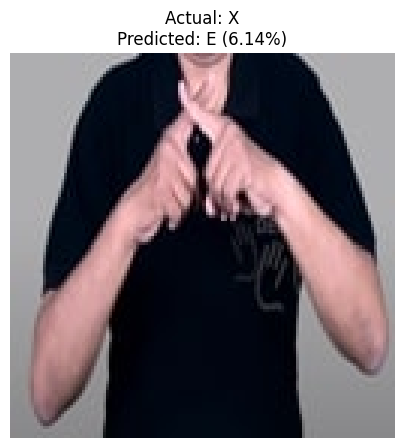

In [41]:
#Run inference on an actual ISL image


# Select an image from the test dataset
sample_path = test_paths[0]

# Get its actual alphabet label
actual_alphabet = classes[int(test_labels[0])]

# Predict using the reloaded model
predicted_alphabet, confidence = predict_isl(
    sample_path,
    loaded_model,
    loaded_classes
)

print("Actual alphabet:", actual_alphabet)
print("Predicted alphabet:", predicted_alphabet)
print(f"Model confidence: {confidence:.2%}")

# Display image
image = Image.open(sample_path).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(image)

plt.title(
    f"Actual: {actual_alphabet}\n"
    f"Predicted: {predicted_alphabet} ({confidence:.2%})"
)

plt.axis("off")
plt.show()


In [42]:
# Compare original and reloaded predictions


# Load one batch from the test dataset
test_images, test_targets = next(iter(test_ds))

# Original model predictions
original_logits = model(
    test_images,
    training=False
).numpy()

# Reloaded model predictions
reloaded_logits = loaded_model(
    test_images,
    training=False
).numpy()

# Compare outputs
outputs_match = np.allclose(
    original_logits,
    reloaded_logits,
    rtol=1e-5,
    atol=1e-6
)

print("Original and reloaded outputs match:", outputs_match)

# Maximum absolute numerical difference
max_difference = np.max(
    np.abs(original_logits - reloaded_logits)
)

print("Maximum prediction difference:", max_difference)


Original and reloaded outputs match: True
Maximum prediction difference: 0.0


In [43]:
#Final TensorFlow report


# Generate final project summary from actual results
print("=" * 55)
print("INDIAN SIGN LANGUAGE — TENSORFLOW PROJECT")
print("=" * 55)

print("\nDATASET")
print("Classes:", len(classes))
print("Total images:", len(image_paths))
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Test images:", len(test_paths))

print("\nMODEL")
print("Architecture: Convolutional Neural Network")
print("Framework: TensorFlow / Keras")
print("Image resolution: 128 x 128")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Epochs:", epochs)

print("\nTEST PERFORMANCE")
print(f"Accuracy: {accuracy:.2%}")
print(f"Macro Precision: {precision:.2%}")
print(f"Macro Recall: {recall:.2%}")
print(f"Macro F1-Score: {f1:.2%}")
print(f"Test Loss: {test_loss:.4f}")

print("\nSAVED MODEL")
print(model_path)

print("\nBUSINESS CONCLUSION")

if accuracy >= 0.90 and f1 >= 0.90:
    print(
        "The model demonstrates strong preliminary performance "
        "on the current test split. External validation with "
        "new signers, backgrounds, and lighting is still needed."
    )

elif accuracy >= 0.70 and f1 >= 0.70:
    print(
        "The model is a promising baseline for ISL recognition. "
        "Further error analysis and model improvement are needed."
    )

else:
    print(
        "The model currently has limited recognition performance. "
        "Prioritize data quality, augmentation, and architecture "
        "improvements before considering deployment."
    )


INDIAN SIGN LANGUAGE — TENSORFLOW PROJECT

DATASET
Classes: 23
Total images: 702
Training images: 561
Validation images: 70
Test images: 71

MODEL
Architecture: Convolutional Neural Network
Framework: TensorFlow / Keras
Image resolution: 128 x 128
Optimizer: Adam
Learning rate: 0.001
Epochs: 10

TEST PERFORMANCE
Accuracy: 8.45%
Macro Precision: 0.83%
Macro Recall: 5.65%
Macro F1-Score: 1.42%
Test Loss: 3.0979

SAVED MODEL
/content/drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/5_Deep_Learning/isl_tensorflow_model.keras

BUSINESS CONCLUSION
The model currently has limited recognition performance. Prioritize data quality, augmentation, and architecture improvements before considering deployment.
